In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Data load

In [49]:
diamonds = sns.load_dataset('diamonds')

In [50]:
diamonds

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


# Task 1

Your dataset includes continuous physical features like `carat`, `depth`, `x`, `y`, `z`, and `price`, as well as discrete human-assigned categories such as `cut`, `color`, and `clarity`.

1. Select only the continuous numerical features for the dimensionality reduction pipeline.
2. Next, apply a StandardScaler to these features.
3. Create a visualisation of your data.

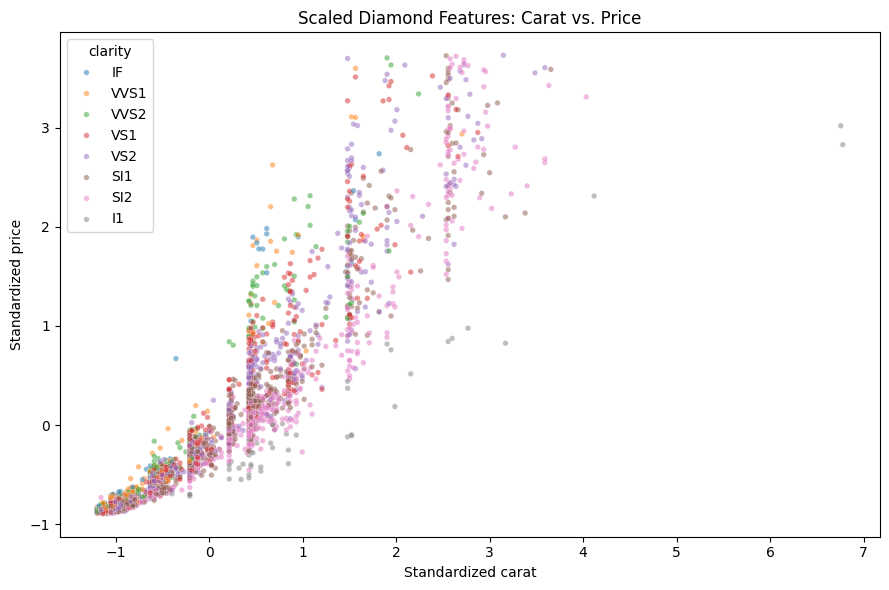

In [51]:
numeric_features = ['carat', 'depth', 'x', 'y', 'z', 'price']
X_diamonds = diamonds[numeric_features]

scaler = StandardScaler()
X_diamonds_scaled = scaler.fit_transform(X_diamonds)
X_diamonds_scaled_df = pd.DataFrame(
    X_diamonds_scaled, columns=numeric_features, index=diamonds.index
)

plot_data = X_diamonds_scaled_df.assign(
    clarity=diamonds['clarity']
).sample(n=3000, random_state=42)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_data, x='carat', y='price', hue='clarity',
    alpha=0.5, s=16
)
plt.title('Scaled Diamond Features: Carat vs. Price')
plt.xlabel('Standardized carat')
plt.ylabel('Standardized price')
plt.tight_layout()
plt.show()

# Task 2

1. Apply a standard PCA model to the scaled numerical data, then create a Scree Plot to show the cumulative variance.

2. Create a 2D scatterplot of the first two Principal Components. Colour each dot by clarity.

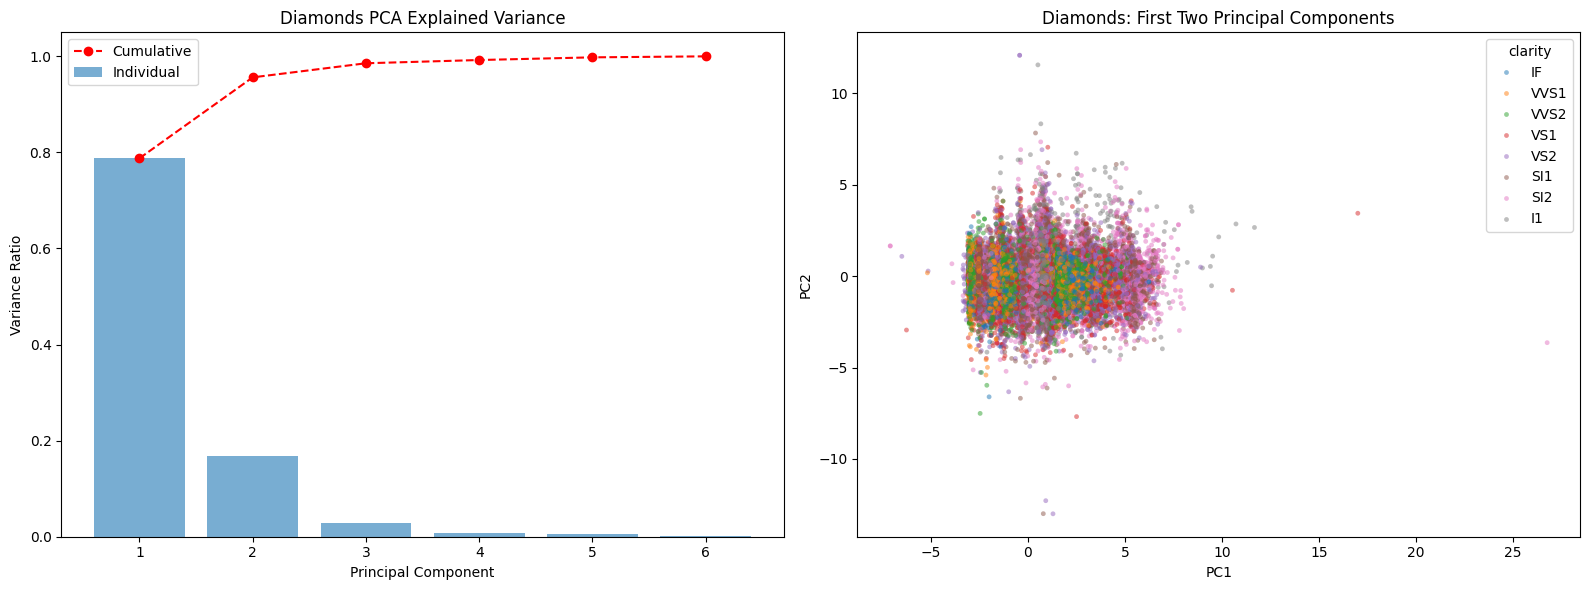

In [52]:
pca_diamonds = PCA().fit(X_diamonds_scaled)
individual_variance = pca_diamonds.explained_variance_ratio_
cumulative_variance = np.cumsum(individual_variance)
X_diamonds_pca = pca_diamonds.transform(X_diamonds_scaled)

component_numbers = np.arange(1, len(individual_variance) + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(component_numbers, individual_variance, alpha=0.6, label='Individual')
axes[0].plot(
    component_numbers, cumulative_variance, marker='o', linestyle='--',
    color='red', label='Cumulative'
)
axes[0].set_title('Diamonds PCA Explained Variance')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Variance Ratio')
axes[0].set_xticks(component_numbers)
axes[0].legend()

sns.scatterplot(
    x=X_diamonds_pca[:, 0], y=X_diamonds_pca[:, 1],
    hue=diamonds['clarity'], palette='tab10', s=12, alpha=0.5,
    linewidth=0, ax=axes[1]
)
axes[1].set_title('Diamonds: First Two Principal Components')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

# Task 3

1. Train an LDA model to predict the `clarity`(8 classes) using the scaled numerical features. 

2. Transform the data, then plot the first two Linear Discriminants (LD1 and LD2).

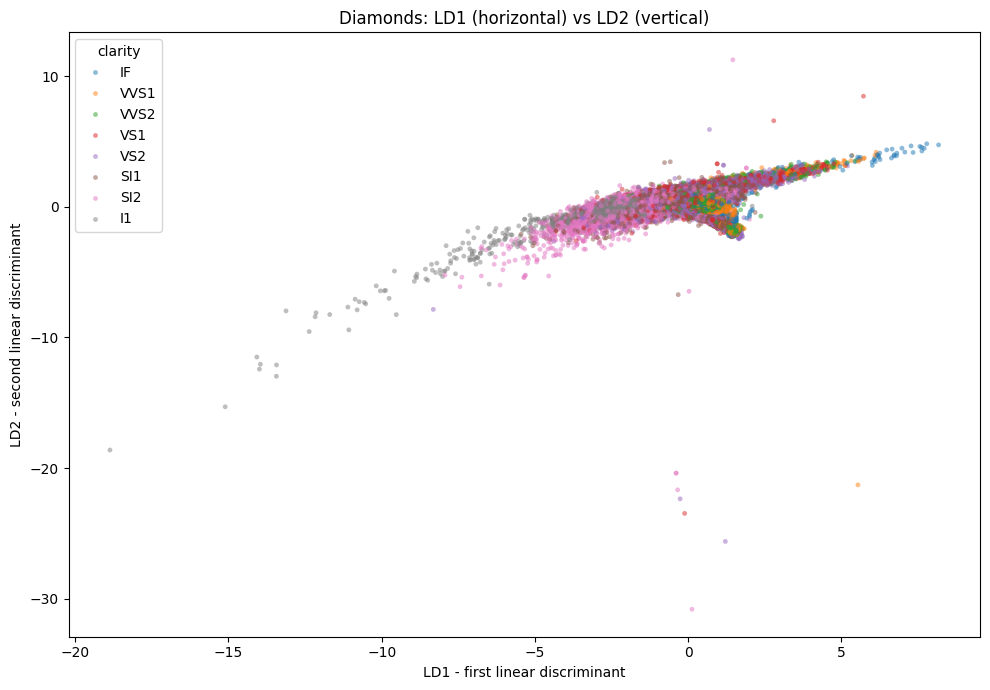

In [53]:
lda_diamonds = LinearDiscriminantAnalysis(n_components=2)
X_diamonds_lda = lda_diamonds.fit_transform(
    X_diamonds_scaled, diamonds['clarity']
)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_diamonds_lda[:, 0], y=X_diamonds_lda[:, 1],
    hue=diamonds['clarity'], palette='tab10', s=12, alpha=0.5,
    linewidth=0
)
plt.title('Diamonds: LD1 (horizontal) vs LD2 (vertical)')
plt.xlabel('LD1 - first linear discriminant')
plt.ylabel('LD2 - second linear discriminant')
plt.tight_layout()
plt.show()

The scatterplot above shows both discriminants: LD1 on the horizontal axis and LD2 on the vertical axis. It uses all rows for visualization.

To compare performance before and after reduction, use the same train/test split and logistic regression model for both. Fit the scaler and supervised LDA transformation on the training set only, then transform the test set. Macro F1 gives each clarity class equal weight.

The separate LDA classifier score is included for comparison with the lesson. Its `n_components=2` controls the transformation, not the dimensions used by LDA's own `predict` method.

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

X_train, X_test, y_train, y_test = train_test_split(
    X_diamonds, diamonds['clarity'], test_size=0.3,
    random_state=42, stratify=diamonds['clarity']
)

evaluation_scaler = StandardScaler().fit(X_train)
X_train_scaled = evaluation_scaler.transform(X_train)
X_test_scaled = evaluation_scaler.transform(X_test)

baseline = LogisticRegression(max_iter=1000).fit(X_train_scaled, y_train)
lda_evaluation = LinearDiscriminantAnalysis(n_components=2).fit(
    X_train_scaled, y_train
)
X_train_lda = lda_evaluation.transform(X_train_scaled)
X_test_lda = lda_evaluation.transform(X_test_scaled)
reduced_model = LogisticRegression(max_iter=1000).fit(X_train_lda, y_train)
baseline_predictions = baseline.predict(X_test_scaled)
reduced_predictions = reduced_model.predict(X_test_lda)
lda_predictions = lda_evaluation.predict(X_test_scaled)

print(f'Before reduction (all features), test macro F1: {f1_score(y_test, baseline_predictions, average="macro"):.4f}')
print(f'After reduction (LD1 and LD2), test macro F1: {f1_score(y_test, reduced_predictions, average="macro"):.4f}')
print(f'LDA classifier (separate comparison), test macro F1: {f1_score(y_test, lda_predictions, average="macro"):.4f}')

classes = lda_evaluation.classes_
pd.DataFrame({
    'clarity': classes,
    'Before reduction F1': f1_score(y_test, baseline_predictions, labels=classes, average=None),
    'After reduction F1': f1_score(y_test, reduced_predictions, labels=classes, average=None),
    'LDA classifier F1': f1_score(y_test, lda_predictions, labels=classes, average=None),
})

Before reduction (all features), test macro F1: 0.2825
After reduction (LD1 and LD2), test macro F1: 0.2495
LDA classifier (separate comparison), test macro F1: 0.2331


,clarity,Before reduction F1,After reduction F1,LDA classifier F1
0,I1,0.560694,0.314286,0.367347
1,IF,0.061962,0.032200,0.025594
2,SI1,0.446591,0.433974,0.436756
3,SI2,0.495972,0.475795,0.470565
4,VS1,0.056180,0.061436,0.000000
5,VS2,0.396546,0.401719,0.362693
6,VVS1,0.068127,0.122795,0.111111
7,VVS2,0.173615,0.153480,0.090661


# Task 4

1. The diamonds dataset contains more than 53,000 rows. Since t-SNE works best with smaller datasets, randomly select exactly 3,000 rows from your dataframe before you continue.

2. Apply t-SNE twice to your sampled and scaled numerical data. Use perplexity 5 for the first run and perplexity 50 for the second.

3. Make a 1x2 subplot grid to show both t-SNE projections. Colour the data points according to diamond `clarity`.

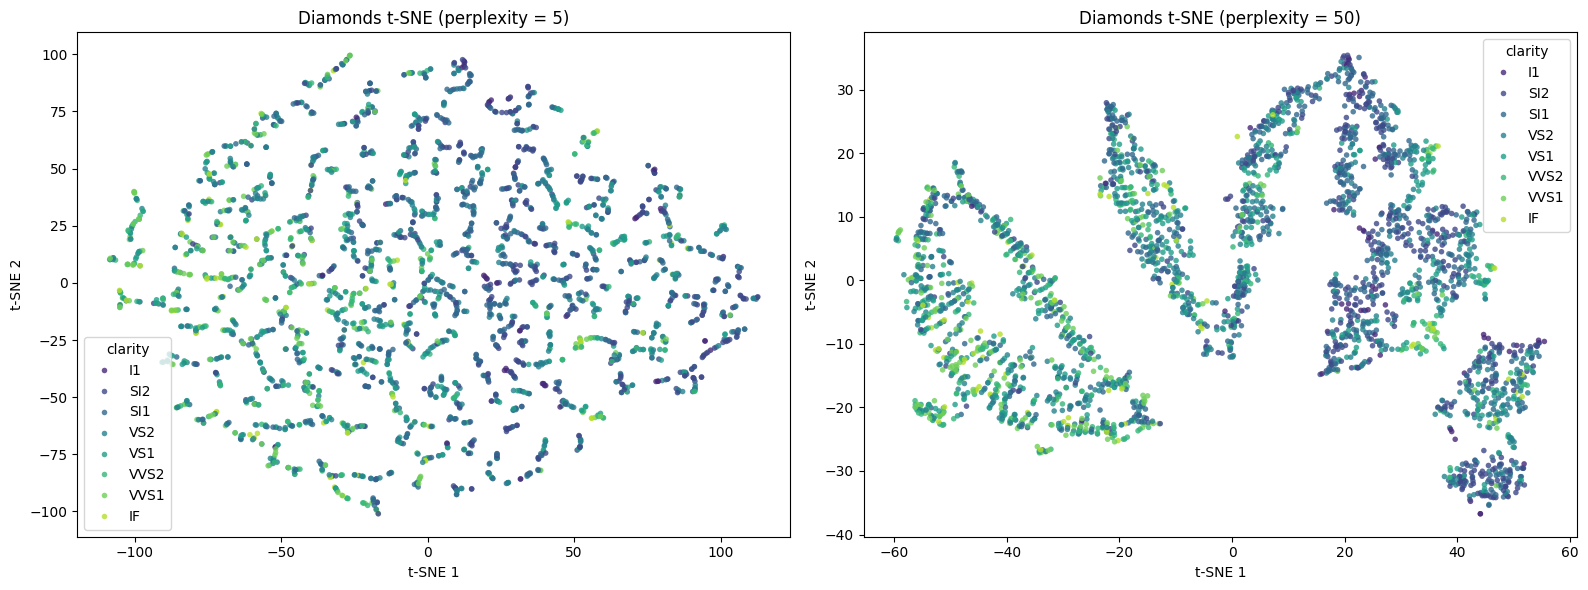

In [55]:
from sklearn.manifold import TSNE

diamonds_sample = diamonds.sample(n=3000, random_state=42).reset_index(drop=True)
X_sample_scaled = scaler.transform(diamonds_sample[numeric_features])
clarity_order = list(reversed(diamonds['clarity'].cat.categories))
clarity_palette = sns.color_palette('viridis', n_colors=len(clarity_order))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, perplexity in zip(axes, [5, 50]):
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42)
    X_sample_tsne = tsne.fit_transform(X_sample_scaled)

    sns.scatterplot(
        x=X_sample_tsne[:, 0], y=X_sample_tsne[:, 1],
        hue=diamonds_sample['clarity'], hue_order=clarity_order,
        palette=clarity_palette, s=16, alpha=0.8, linewidth=0, ax=ax
    )
    ax.set_title(f'Diamonds t-SNE (perplexity = {perplexity})')
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')

plt.tight_layout()
plt.show()

# Task 5

1. Apply UMAP to the scaled numerical features.

2. Create a 1x2 subplot grid. On the left, plot UMAP with `min_dist = 0.05`. On the right, plot UMAP with `min_dist = 0.8`. Colour both by clarity.

c:\Users\keiron.jones.TETRAD\Programming\Apprenticeship\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


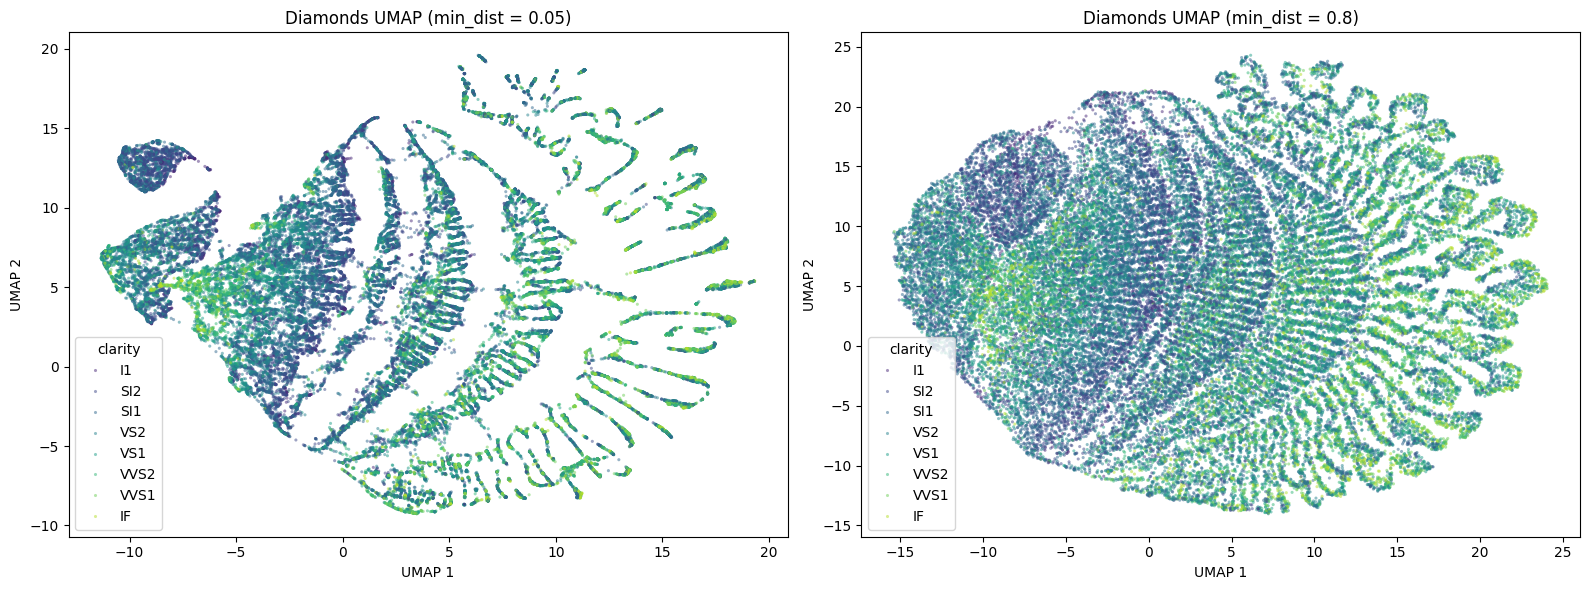

In [56]:
import umap

clarity_order = list(reversed(diamonds['clarity'].cat.categories))
clarity_palette = sns.color_palette('viridis', n_colors=len(clarity_order))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, min_dist in zip(axes, [0.05, 0.8]):
    umap_model = umap.UMAP(
        n_components=2, n_neighbors=15, min_dist=min_dist,
        random_state=42, n_jobs=1
    )
    X_diamonds_umap = umap_model.fit_transform(X_diamonds_scaled)

    sns.scatterplot(
        x=X_diamonds_umap[:, 0], y=X_diamonds_umap[:, 1],
        hue=diamonds['clarity'], hue_order=clarity_order,
        palette=clarity_palette, s=5, alpha=0.5, linewidth=0, ax=ax
    )
    ax.set_title(f'Diamonds UMAP (min_dist = {min_dist})')
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

plt.tight_layout()
plt.show()